# Synthetic ESIS-II Images

This report forward-models a single ESIS-II detector frame from a real solar scene:
the active-region pair NOAA 12565 and 12567 observed by SDO/AIA on 2016 July 15 at
00:00 UT.

The scene is `esis.flights.f2.data.synth.scene_dem()`.
The differential emission measure (DEM) of each AIA pixel is inverted from the six
optically thin EUV channels with `utu.dem.plowman()`, against the CHIANTI 11
temperature response of `sdo.aia.temperature_response()`,
and the spectrum of the plasma it describes is computed from the CHIANTI atomic
database with `utu.spectrum`, for every line in the ESIS-II passband which
carries at least half a percent of its radiance.
Each line is spread over bins of velocity by the thermal motion of its ions, at rest.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
import astropy.visualization
import named_arrays as na
import optika
import esis

## The scene

The axes of the AIA pixels are renamed, so that they can't be mistaken for the
axes of the ESIS-II detector the scene is imaged onto.
The first call downloads the AIA images and computes the contribution functions of
the lines, which takes about a quarter of an hour; both are cached afterwards.

In [2]:
axis_x = "scene_x"
axis_y = "scene_y"

scene = esis.flights.f2.data.synth.scene_dem(
    axis_detector_x=axis_x,
    axis_detector_y=axis_y,
)
scene.outputs.shape

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

aiapy.aia_pointing_table.csv:   0%|          | 0.00/4.91M [00:00<?, ?B/s]

2026-10-15 17:38:30 - fiasco - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


2026-10-15 17:38:32 - fiasco - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


2026-10-15 17:38:34 - fiasco - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


...

2026-10-15 17:52:42 - fiasco - WARNING: No proton data available for Fe 17. Not including proton excitation and de-excitation in level populations calculation.


2026-10-15 17:55:57 - fiasco - WARNING: No proton data available for Fe 24. Not including proton excitation and de-excitation in level populations calculation.


2026-10-15 17:56:02 - fiasco - WARNING: No proton data available for Fe 24. Not including proton excitation and de-excitation in level populations calculation.


2026-10-15 17:56:27 - fiasco - WARNING: No proton data available for Fe 25. Not including proton excitation and de-excitation in level populations calculation.


{'line': 22, 'scene_y': 833, 'scene_x': 834, 'velocity': 20}

The radiance of each line is its spectral radiance summed over its bins of
velocity. The two lines ESIS-II was designed for are the brightest, followed by the
weaker line of the Si XII doublet and the Mg VII and Mg VIII lines at the short end of
the passband.

In [3]:
width = np.diff(scene.inputs.wavelength, axis="velocity")
radiance = (scene.outputs * width).sum("velocity")

rest = scene.inputs.wavelength_rest
mean = radiance.mean((axis_x, axis_y))
fraction = mean / mean.sum("line")

print(f"{'wavelength':>12}{'radiance':>12}{'fraction':>10}")
for i in np.argsort(-mean.ndarray.value):
    index = dict(line=i)
    print(
        f"{rest[index].ndarray.to_value(u.AA):12.3f}"
        f"{mean[index].ndarray.value:12.1f}"
        f"{fraction[index].ndarray.value:10.3f}"
    )

  wavelength    radiance  fraction
     499.406       291.5     0.271
     465.221       234.5     0.218
     520.665       141.1     0.131
     436.733        86.1     0.080
     434.927        52.7     0.049
     430.454        52.4     0.049
     431.323        30.9     0.029
     435.646        22.6     0.021
     447.357        20.7     0.019
     443.973        17.5     0.016
     467.427        15.6     0.014
     445.700        14.2     0.013
     433.179        14.2     0.013
     510.042        13.5     0.013
     482.994        11.5     0.011
     481.489         9.2     0.009
     431.198         8.7     0.008
     436.660         8.4     0.008
     487.042         8.3     0.008
     444.219         8.0     0.007
     434.730         7.8     0.007
     439.176         6.1     0.006


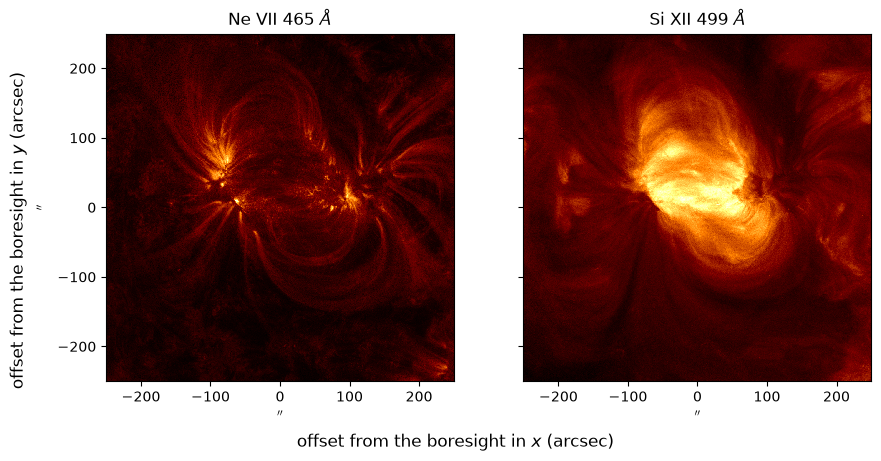

In [4]:
lines = {
    r"Ne VII 465 $\AA$": esis.flights.f2.wavelength_Ne_VII,
    r"Si XII 499 $\AA$": esis.flights.f2.wavelength_Si_XII,
}

with astropy.visualization.quantity_support():
    fig, axs = plt.subplots(
        ncols=2,
        figsize=(9, 4.5),
        sharey=True,
        constrained_layout=True,
    )
    for ax, (name, w) in zip(axs, lines.items()):
        index = np.argmin(np.abs(rest - w), axis="line")
        na.plt.pcolormesh(
            scene.inputs.position,
            C=np.sqrt(radiance[index].value),
            ax=ax,
            cmap="afmhot",
        )
        ax.set_title(name)
        ax.set_aspect("equal")
    fig.supxlabel("offset from the boresight in $x$ (arcsec)")
    fig.supylabel("offset from the boresight in $y$ (arcsec)")

## The instrument

The forward model is a single channel of the current ESIS-II design.
Replacing the sensor material with an ideal one, which counts one electron per
absorbed photon, and exposing for one second makes the frame read directly in
photons per second per pixel.

In [5]:
instrument = esis.flights.f2.optics.design_single(num_distribution=0)
system = instrument.system
system.sensor.material = optika.sensors.materials.IdealSensorMaterial()
system.sensor.timedelta_exposure = 1 * u.s

## Projection onto the detector

Each line is imaged through a linear approximation of the optical system,
`optika.systems.SequentialSystem.linearize()`, which fits the distortion,
vignetting, effective area, and field stop of the system and then images the scene by
conservative regridding, without the sampling noise of a ray trace.
The fits are polynomials in wavelength, so each line is linearized on five
wavelengths spanning two angstroms around it.

In [6]:
frame = 0

for i in range(rest.shape["line"]):
    index = dict(line=i)
    w = rest[index]

    linear = system.linearize(
        wavelength=na.linspace(w - 1 * u.AA, w + 1 * u.AA, axis="_wavelength", num=5),
        degree=2,
    )

    image = linear.image(
        scene=scene[index],
        axis_wavelength="velocity",
        axis_field=(axis_x, axis_y),
        noise=False,
    )

    frame = frame + image.outputs.to(u.electron)

2026-10-15 17:57:21 - fiasco - WARNING: function 'sqrt' is not known to astropy's Quantity. Will run it anyway, hoping it will treat ndarray subclasses correctly. Please raise an issue at https://github.com/astropy/astropy/issues.


2026-10-15 17:57:35 - fiasco - WARNING: function 'sqrt' is not known to astropy's Quantity. Will run it anyway, hoping it will treat ndarray subclasses correctly. Please raise an issue at https://github.com/astropy/astropy/issues.


## The synthetic frame

The Ne VII and Si XII images of the octagonal field stop land side by side on the
detector, on either side of its center.
Ne VII shows the cool fan loops and moss of the two active regions, and Si XII their
hot cores.
The fainter octagons to the left are the Mg VII and Mg VIII lines, and the one to the
right is the weaker line of the Si XII doublet.

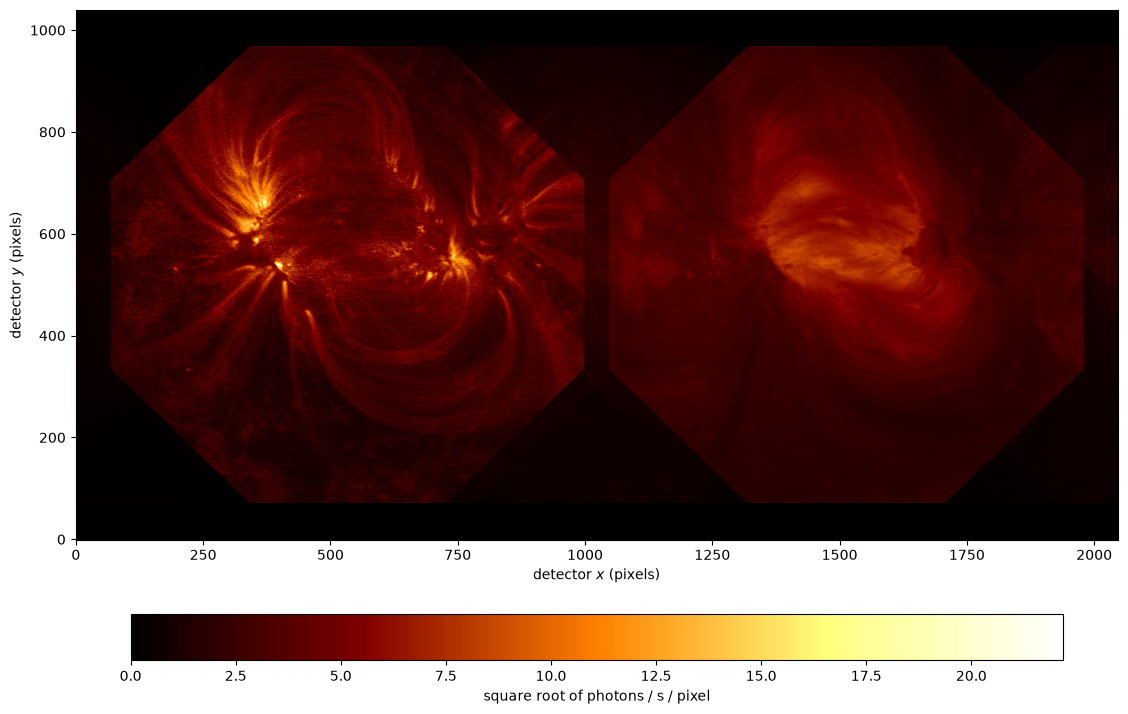

In [7]:
rate = frame.value.ndarray_aligned(("detector_y", "detector_x"))

fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
img = ax.imshow(
    np.sqrt(np.clip(rate, 0, None)),
    origin="lower",
    cmap="afmhot",
    interpolation="none",
)
ax.set_xlabel("detector $x$ (pixels)")
ax.set_ylabel("detector $y$ (pixels)")
colorbar = fig.colorbar(img, ax=ax, orientation="horizontal", shrink=0.8)
colorbar.set_label("square root of photons / s / pixel")